In [ ]:
# kmeans_mapreduce.py

import math


# ---------------- MAP ----------------
def mapper(data_points, centroids):
    """
    Assign each data point to the nearest centroid.
    Output: (cluster_id, point)
    """
    mapped = []

    for point in data_points:
        min_distance = float("inf")
        nearest_cluster = None

        for cluster_id, centroid in centroids.items():
            distance = math.sqrt(
                (point[0] - centroid[0]) ** 2 +
                (point[1] - centroid[1]) ** 2
            )

            if distance < min_distance:
                min_distance = distance
                nearest_cluster = cluster_id

        mapped.append((nearest_cluster, point))

    return mapped


# ---------------- SHUFFLE ----------------
def shuffle(mapped_data):
    """
    Group points according to their cluster.
    """
    grouped = {}

    for cluster_id, point in mapped_data:
        if cluster_id not in grouped:
            grouped[cluster_id] = []

        grouped[cluster_id].append(point)

    return grouped


# ---------------- REDUCE ----------------
def reducer(grouped_data):
    """
    Calculate the new centroid of each cluster.
    """
    new_centroids = {}

    for cluster_id, points in grouped_data.items():
        x_sum = sum(point[0] for point in points)
        y_sum = sum(point[1] for point in points)

        x_mean = x_sum / len(points)
        y_mean = y_sum / len(points)

        new_centroids[cluster_id] = (x_mean, y_mean)

    return new_centroids


# ---------------- K-MEANS ----------------
def kmeans(data_points, centroids, iterations=10):

    for i in range(iterations):

        print("\nIteration:", i + 1)
        print("Centroids:", centroids)

        # Map
        mapped_data = mapper(data_points, centroids)

        # Shuffle
        grouped_data = shuffle(mapped_data)

        # Reduce
        new_centroids = reducer(grouped_data)

        # Check convergence
        if new_centroids == centroids:
            break

        centroids = new_centroids

    return centroids


# ---------------- MAIN ----------------

data_points = [
    (1, 1),
    (2, 2),
    (1, 2),
    (8, 8),
    (9, 9),
    (8, 9)
]

# Initial centroids
centroids = {
    0: (1, 1),
    1: (8, 8)
}

final_centroids = kmeans(
    data_points,
    centroids,
    iterations=10
)

print("\nFinal Centroids:")
for cluster, centroid in final_centroids.items():
    print("Cluster", cluster, ":", centroid)



Iteration: 1
Centroids: {0: (1, 1), 1: (8, 8)}

Iteration: 2
Centroids: {0: (1.3333333333333333, 1.6666666666666667), 1: (8.333333333333334, 8.666666666666666)}

Final Centroids:
Cluster 0 : (1.3333333333333333, 1.6666666666666667)
Cluster 1 : (8.333333333333334, 8.666666666666666)


Converged at iteration 4


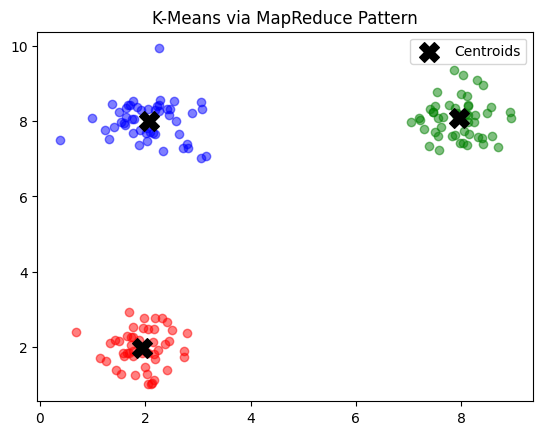

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from typing import List, Tuple, Dict

# --- 1. MAPPER ---
def mapper(data_points: np.ndarray, centroids: np.ndarray) -> List[Tuple[int, np.ndarray]]:
    """Assigns each point to the nearest centroid (Cluster ID)."""
    assignments = []
    for point in data_points:
        # Calculate Euclidean distance to all centroids
        distances = np.linalg.norm(point - centroids, axis=1)
        cluster_id = np.argmin(distances)
        assignments.append((cluster_id, point))
    return assignments

# --- 2. SHUFFLE (Simulated) ---
def shuffle_and_sort(mapped_data: List[Tuple[int, np.ndarray]]) -> Dict[int, List[np.ndarray]]:
    """Groups points by their assigned cluster ID."""
    shuffled = {}
    for cluster_id, point in mapped_data:
        if cluster_id not in shuffled:
            shuffled[cluster_id] = []
        shuffled[cluster_id].append(point)
    return shuffled

# --- 3. REDUCER ---
def reducer(cluster_id: int, points: List[np.ndarray]) -> Tuple[int, np.ndarray]:
    """Calculates the new centroid (mean) for a specific cluster."""
    new_centroid = np.mean(points, axis=0)
    return (cluster_id, new_centroid)

# --- MAPREDUCE K-MEANS ORCHESTRATOR ---
def run_kmeans_mapreduce(data: np.ndarray, k: int, max_iter: int = 10):
    # Randomly initialize centroids
    indices = np.random.choice(len(data), k, replace=False)
    centroids = data[indices]

    for i in range(max_iter):
        # Step 1: Map
        mapped = mapper(data, centroids)

        # Step 2: Shuffle
        grouped = shuffle_and_sort(mapped)

        # Step 3: Reduce
        new_centroids_dict = {}
        for cluster_id, points in grouped.items():
            cid, new_c = reducer(cluster_id, points)
            new_centroids_dict[cid] = new_c

        # Convert dict back to sorted array for next iteration
        new_centroids = np.array([new_centroids_dict[i] for i in range(k)])

        # Convergence check
        if np.allclose(centroids, new_centroids):
            print(f"Converged at iteration {i+1}")
            break
        centroids = new_centroids

    return centroids, mapped

# --- EXECUTION & VISUALIZATION ---
# Generate dummy data
np.random.seed(42)
X = np.vstack([
    np.random.normal(loc=(2, 2), scale=0.5, size=(50, 2)),
    np.random.normal(loc=(8, 8), scale=0.5, size=(50, 2)),
    np.random.normal(loc=(2, 8), scale=0.5, size=(50, 2))
])

# Run Algorithm
final_centroids, final_assignments = run_kmeans_mapreduce(X, k=3)

# Plotting
colors = ['red', 'blue', 'green']
for cluster_id, point in final_assignments:
    plt.scatter(point[0], point[1], color=colors[cluster_id], alpha=0.5)

plt.scatter(final_centroids[:, 0], final_centroids[:, 1], c='black', marker='X', s=200, label='Centroids')
plt.title("K-Means via MapReduce Pattern")
plt.legend()
plt.show()